# 5. Double factorization

A molecule with $n$ spatial orbitals has about $n^4/8$ distinct two-electron integrals, so its Pauli sum has $O(n^4)$ terms to load and a large one-norm $\lambda$. Rewriting the two-electron part as a sum of squares of one-body operators cuts both. How, and what does the truncation cost in accuracy?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyscf import fci

from qcost.factorization import df_lambda, double_factorize, h_chain, pauli_sum, rebuild_eri

## The recipe on four hydrogen atoms

`h_chain(4)` runs Hartree–Fock for H$_4$ in a minimal basis (bond length 1.4 bohr) and returns the one-electron integrals $h_{pq}$ and two-electron integrals $(pq|rs)$ in the molecular orbitals: 4 spatial orbitals, 8 spin orbitals.

In [2]:
h1, eri = h_chain(4)
n = h1.shape[0]
factors, L, LXi = double_factorize(eri, thresh=1e-4)
lam = df_lambda(h1, eri, factors)
print(f"{n} orbitals: first rank L = {L}, eigenvectors kept L*Xi = {LXi}")
print(f"lambda: Pauli sum {pauli_sum(h1, eri).one_norm:.2f},  double factorized {lam['total']:.2f}"
      f"  (one-body {lam['one-body']:.2f} + two-body {lam['two-body']:.2f})")

4 orbitals: first rank L = 9, eigenvectors kept L*Xi = 36


lambda: Pauli sum 8.75,  double factorized 5.96  (one-body 2.27 + two-body 3.68)


## Step 1: the integrals as a matrix

Group the indices in pairs: $V_{(pq),(rs)} = (pq|rs)$ is an $n^2\times n^2$ matrix, symmetric and positive semidefinite (it is a Coulomb interaction between charge densities). Its eigendecomposition writes it as a sum of $L$ outer products,
$$(pq|rs) = \sum_{\ell=1}^{L} W^{\ell}_{pq}\,W^{\ell}_{rs},$$
and the eigenvalues fall fast:

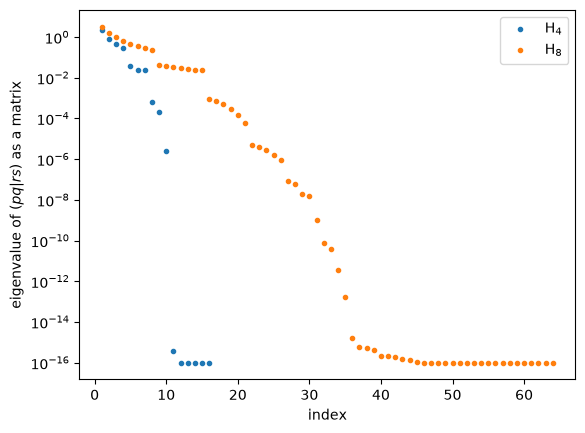

In [3]:
for atoms in (4, 8):
    _, e8 = h_chain(atoms)
    ev = np.sort(np.linalg.eigvalsh(e8.reshape(atoms**2, atoms**2)))[::-1]
    plt.semilogy(np.arange(1, len(ev) + 1), np.clip(ev, 1e-16, None), ".", label=f"H$_{{{atoms}}}$")
plt.xlabel("index")
plt.ylabel(r"eigenvalue of $(pq|rs)$ as a matrix")
plt.legend();

In second quantization this turns the two-body part into a sum of squares, $\tfrac12\sum_\ell \big(\sum_{pq,\sigma} W^\ell_{pq} a^\dagger_{p\sigma}a_{q\sigma}\big)^2$, plus a one-body correction, $T'_{pq} = h_{pq} - \tfrac12\sum_r (pr|rq) + \sum_r (rr|pq)$ [von Burg et al., [arXiv:2007.14460](https://arxiv.org/abs/2007.14460); Lee et al., [arXiv:2011.03494](https://arxiv.org/abs/2011.03494), App. C].

## Step 2: each square, in its own orbitals

Each $W^\ell$ is a symmetric $n\times n$ matrix, so it has its own eigenbasis: $W^\ell = U^\ell\,\mathrm{diag}(f^\ell)\,U^{\ell T}$. In those rotated orbitals the one-body operator is a sum of number operators, $\sum_m f^\ell_m n_m$. The block encoding of one square is then: rotate the orbitals (Givens rotations, angles from a lookup), apply number operators (Pauli $Z$s), rotate back. Small eigenvalues are dropped: eigenvector $m$ of $W^\ell$ is kept if $\big(\sum_p |f^\ell_p|\big)\,|f^\ell_m| >$ threshold, and the first $\ell$ that keeps nothing ends the list [Lee et al., Eq. C41]. The rebuilt integrals:

In [4]:
h1, eri = h_chain(6)
for thresh in (1e-2, 1e-3, 1e-4, 1e-6):
    f, L, LXi = double_factorize(eri, thresh)
    err = np.abs(rebuild_eri(f) - eri).max()
    print(f"threshold {thresh:7.0e}: L = {L:2d}, L*Xi = {LXi:3d}, largest integral error {err:.1e}")

threshold   1e-02: L = 11, L*Xi =  56, largest integral error 1.0e-03
threshold   1e-03: L = 11, L*Xi =  62, largest integral error 2.6e-04
threshold   1e-04: L = 15, L*Xi =  80, largest integral error 2.7e-05
threshold   1e-06: L = 18, L*Xi = 104, largest integral error 1.3e-07


## The one-norm

The walk pays $\lambda$ through the number of phase-estimation steps (notebook 04). For the factorized form [Lee et al., Eq. C11]
$$\lambda = \sum_{p}|\text{eig}_p(T')| + \frac14\sum_\ell\Big(\sum_m |f^\ell_m|\Big)^2 .$$
A live run on chains of 2 to 8 atoms, then the full run to 20 atoms, from `scripts/make_results.py` (about 10 seconds):

In [5]:
for atoms in (2, 4, 6, 8):
    h1, eri = h_chain(atoms)
    f, L, LXi = double_factorize(eri, 1e-4)
    print(f"H{atoms}: Pauli {pauli_sum(h1, eri).one_norm:6.1f}   DF {df_lambda(h1, eri, f)['total']:6.1f}")

H2: Pauli    1.9   DF    1.7
H4: Pauli    8.8   DF    6.0


H6: Pauli   21.4   DF   12.1
H8: Pauli   40.4   DF   19.9


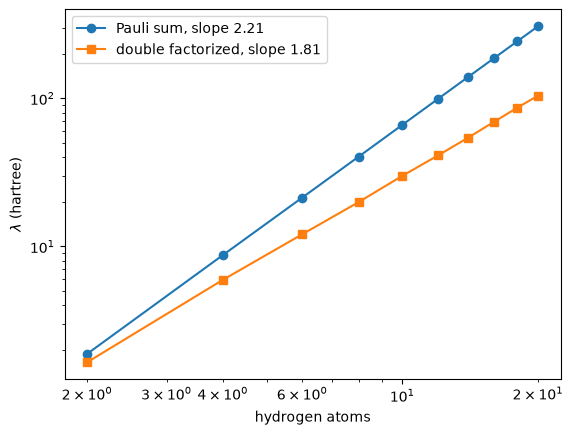

In [6]:
rows = json.loads(Path("../results/hydrogen_chains.json").read_text())
atoms = np.array([r["atoms"] for r in rows])
lp = np.array([r["lambda_pauli"] for r in rows])
ld = np.array([r["lambda_df"] for r in rows])


def fit(y):
    return np.polyfit(np.log(atoms[3:]), np.log(y[3:]), 1)[0]



plt.loglog(atoms, lp, "o-", label=f"Pauli sum, slope {fit(lp):.2f}")
plt.loglog(atoms, ld, "s-", label=f"double factorized, slope {fit(ld):.2f}")
plt.xlabel("hydrogen atoms")
plt.ylabel(r"$\lambda$ (hartree)")
plt.legend();

Both grow faster than the number of atoms, but the factorized one-norm grows more slowly, and the gap widens: a factor 2.9 at 20 atoms. Since the walk-call count is proportional to $\lambda$, that factor goes straight into the run time.

## What truncation costs in accuracy

Dropping eigenvectors changes the Hamiltonian. The honest check is the energy: exact diagonalization (full configuration interaction) with the full integrals and with the rebuilt ones, for H$_6$, against the 1.6 mHa of chemical accuracy:

threshold 1.0e-01: L*Xi =  36, energy error 3.3e-02
threshold 3.2e-02: L*Xi =  41, energy error 3.5e-02
threshold 1.0e-02: L*Xi =  56, energy error 6.0e-03
threshold 3.2e-03: L*Xi =  61, energy error 1.7e-04
threshold 1.0e-03: L*Xi =  62, energy error 1.2e-04
threshold 3.2e-04: L*Xi =  74, energy error 3.6e-04
threshold 1.0e-04: L*Xi =  80, energy error 4.7e-07
threshold 3.2e-05: L*Xi =  88, energy error 1.8e-06
threshold 1.0e-05: L*Xi =  88, energy error 1.8e-06


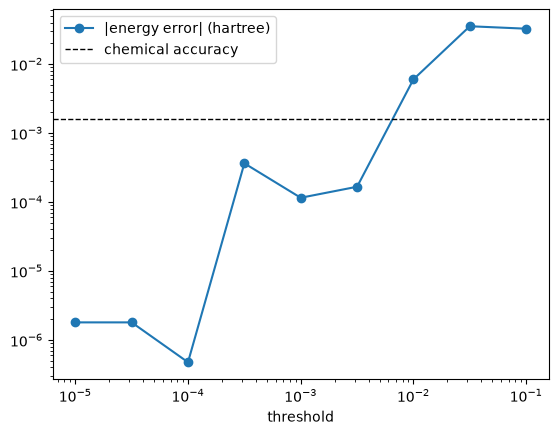

In [7]:
h1, eri = h_chain(6)
nelec = (3, 3)
E_full = fci.direct_spin1.kernel(h1, eri, 6, nelec)[0]
threshs = np.logspace(-1, -5, 9)
errs, sizes = [], []
for t in threshs:
    f, L, LXi = double_factorize(eri, t)
    errs.append(abs(fci.direct_spin1.kernel(h1, rebuild_eri(f), 6, nelec)[0] - E_full))
    sizes.append(LXi)
plt.loglog(threshs, errs, "o-", label="|energy error| (hartree)")
plt.axhline(1.6e-3, color="k", lw=1, ls="--", label="chemical accuracy")
plt.xlabel("threshold")
plt.legend()
for t, e, s in zip(threshs, errs, sizes, strict=True):
    print(f"threshold {t:7.1e}: L*Xi = {s:3d}, energy error {e:.1e}")

The error falls by four orders of magnitude between thresholds $10^{-2}$ and $10^{-4}$, but not smoothly: the dropped pieces have both signs and partly cancel, so a smaller threshold can give a slightly larger error. A threshold is a dial on the number of eigenvectors, and the energy has to be checked.

For large molecules exact diagonalization is out of reach; Lee et al. choose the threshold so that the CCSD(T) energy moves by less than 0.6 mHa, keeping 1 mHa for phase estimation [Eq. 25]. Notebook 08 uses their FeMoco threshold.

## What it does to the cost

The factorized walk's dominant cost is loading the Givens-rotation angles for the $L\Xi$ eigenvectors: a select/swap lookup of $L\Xi$ words of $N\beth/2$ bits (notebook 03), plus $4N(\beth - 2)$ Toffolis of rotations (notebook 02). That lookup is why the factorized estimate in notebook 00 used more qubits than the Pauli sum. The full step list is in notebook 08.

## Exercises

1. Stretch the H$_6$ chain (spacing 2.5 bohr) and repeat the truncation scan. Does the same threshold still reach chemical accuracy?
2. The single factorization keeps $W^\ell$ whole instead of diagonalizing it. Compute its one-norm, $\sum|\text{eig}\,T'| + \frac14\sum_\ell \big(\sum_{pq}|W^\ell_{pq}|\big)^2$, for the hydrogen chains and compare.
3. Count the Pauli terms of each hydrogen chain (`len(pauli_sum(h1, eri).terms)`) and fit the growth with the number of atoms.